## 1. Imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy

import matplotlib.dates as mdates
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import FuncFormatter

## 2. Import data

In [84]:
train = pd.read_csv('../data/traindata_total.csv')
train = train.drop(columns = ['index', 'Service:RDT-ID'])
train = train[(train['Service:Date'] > '2025-12-15') & (train['Service:Date'] < '2026-04-30')]

train.head()

,Service:Date,Service:Type,Service:Company,Service:Train number,Service:Completely cancelled,Service:Partly cancelled,Service:Maximum delay,Stop:RDT-ID,Stop:Station code,Stop:Station name,Stop:Arrival time,Stop:Arrival delay,Stop:Arrival cancelled,Stop:Departure time,Stop:Departure delay,Stop:Departure cancelled,Stop:Platform change,Stop:Planned platform,Stop:Actual platform
19810,2025-12-16,Intercity,NS,1410,False,False,0,157461873,UT,Utrecht Centraal,2025-12-16T03:48:00+01:00,0.0,False,NaN,NaN,NaN,False,15.0,15.0
19811,2025-12-16,Intercity,NS,1409,False,False,1,157461874,UT,Utrecht Centraal,NaN,NaN,NaN,2025-12-16T02:16:00+01:00,0.0,False,False,18.0,18.0
19812,2025-12-16,Intercity,NS,1414,False,False,0,157461887,UT,Utrecht Centraal,2025-12-16T04:48:00+01:00,0.0,False,NaN,NaN,NaN,False,19.0,19.0
19813,2025-12-16,Intercity,NS,1413,False,False,0,157461888,UT,Utrecht Centraal,NaN,NaN,NaN,2025-12-16T03:16:00+01:00,0.0,False,False,18.0,18.0
19814,2025-12-16,Nightjet,202,402,False,False,0,157461903,UT,Utrecht Centraal,2025-12-16T08:52:00+01:00,0.0,False,2025-12-16T08:55:00+01:00,0.0,False,False,14.0,14.0


## 3. Data cleaning & modification

In [85]:
train = train.rename(columns={
        'Service:Type': 'Type',
        'Service:Date': 'Date',
        'Stop:Arrival time': 'scheduled_arrival',
        'Stop:Departure time': 'scheduled_departure',
        'Stop:Arrival cancelled': 'arr_cancelled',
        'Stop:Departure cancelled': 'dep_cancelled',
        'Stop:Arrival delay': 'arr_delay',
        'Stop:Departure delay': 'dep_delay'
    })

train.columns = (train.columns
                     .str.replace('Service:', '', regex=False)
                     .str.replace('Stop:', '', regex=False)
                     .str.replace('RDT-ID', 'train_id', regex=False))

cols_drop = [
        'Completely cancelled', 'Partly cancelled', 'Maximum delay',
        'Train number', 'Station name', 'Station code',
        'Platform change', 'Planned platform', 'Actual platform', 'Company'
    ]

train = train.drop(columns=cols_drop)
train = train[train['Type'].isin(['Intercity', 'Sprinter'])]

time_cols = ['scheduled_arrival', 'scheduled_departure']
train[time_cols] = train[time_cols].apply(
        lambda col: pd.to_datetime(col, utc=True).dt.strftime('%H:%M')
    )


for time, delay in [
    ('arrival', 'arr_delay'),
    ('departure', 'dep_delay')
]:
    train[f'scheduled_{time}'] = pd.to_datetime(
        train[f'scheduled_{time}'], format='%H:%M'
    )

    train[f'actual_{time}'] = (
        train[f'scheduled_{time}'] +
        pd.to_timedelta(train[delay], unit='m')
    )

    train[f'scheduled_{time}'] = train[f'scheduled_{time}'].dt.strftime('%H:%M')
    train[f'actual_{time}'] = train[f'actual_{time}'].dt.strftime('%H:%M')


train['arr_hour'] = pd.to_datetime(
        train['actual_arrival'], format='%H:%M', errors='coerce'
    ).dt.hour

train['dep_hour'] = pd.to_datetime(
        train['actual_departure'], format='%H:%M', errors='coerce'
    ).dt.hour

train = train[
        train['dep_hour'].between(5, 22) &
        train['arr_hour'].between(5, 22)
    ]

train['Date'] = pd.to_datetime(train['Date'])
train['week'] = train['Date'].dt.isocalendar().week

train = train.sort_values(
        ['Date', 'actual_arrival']
    ).reset_index(drop=True)

In [86]:
missing_actuals = train[train['actual_arrival'].isna() & train['actual_departure'].isna()]

cols = ['train_id', 'actual_arrival', 'actual_departure'] # Also none only on train_id (all unique)
duplicates = train[train.duplicated(cols, keep=False)].sort_values(cols)


print(f"Number of duplicates found: {len(duplicates)}")
print(f"Number of trains with missing actual arrival or departure times: {len(missing_actuals)} (passing through station or data errors)")

Number of duplicates found: 0
Number of trains with missing actual arrival or departure times: 0 (passing through station or data errors)


Additionally: https://nsannualreport.nl/annual-report-2025/performance-what-we-have-achieved/our-operations/performance-agreements

In [87]:
# Initializing new variable to flag delay and delay with a three minute threshold
train['arrival_delayed'] = train['arr_delay'] > 0
train['departure_delayed'] = train['dep_delay'] > 0
train['arrival_delayed_3'] = train['arr_delay'] >= 3
train['departure_delayed_3'] = train['dep_delay'] >= 3

# Train is cancelled if either arrival or departure is cancelled. Fill NaN values with False for this.
train['cancelled'] = train['arr_cancelled'].fillna(False) | train['dep_cancelled'].fillna(False)

In [88]:
train['Date'] = pd.to_datetime(train['Date'], errors='coerce')

daily_cancellations = train.groupby(
        train['Date'].dt.normalize()
    )['cancelled'].sum()

cancellation_percentile = 90
threshold = np.percentile(daily_cancellations, cancellation_percentile)
excluded_days = daily_cancellations[
        daily_cancellations > threshold
    ].index

filtered_train = train[
        ~train['Date'].dt.normalize().isin(excluded_days)
    ].copy()

print('\nCANCELLATION-DAY FILTER')
print(f'Percentile used: {cancellation_percentile}th')
print(f'Cancellation threshold: {threshold:.1f} per day')
print(f'Days excluded: {len(excluded_days)} of {len(daily_cancellations)}')
print(f'Trains removed: {len(train) - len(filtered_train)}')
print(f'Trains remaining: {len(filtered_train)}')


CANCELLATION-DAY FILTER
Percentile used: 90th
Cancellation threshold: 202.0 per day
Days excluded: 14 of 135
Trains removed: 12480
Trains remaining: 83753


In [89]:
train = train[
    [
        'Date', 'train_id','Type',
        'scheduled_arrival', 'actual_arrival',
        'scheduled_departure', 'actual_departure',
        'arr_delay', 'dep_delay',
        'arr_cancelled', 'dep_cancelled',
        'arr_hour', 'dep_hour',
        'arrival_delayed', 'departure_delayed',
        'arrival_delayed_3', 'departure_delayed_3',
        'cancelled', 'week'
    ]
]

## 4. Data Analysis

##### 4.1 Delays and cancellations in numbers

In [90]:
delayed_trains = (len(train[(train['arrival_delayed'] == True) | (train['departure_delayed'] == True)])) / len(train) * 100
delayed_operations = len(train[(train['arrival_delayed_3'] == True) | (train['departure_delayed_3'] == True)]) / len(train) * 100
total_cancellations = len(train[train['cancelled'] == True])
total_cancellations_perct = total_cancellations / len(train) * 100


arrival_ids = set(train.loc[train['arr_cancelled'] == True, 'train_id'])
departure_ids = set(train.loc[train['dep_cancelled'] == True, 'train_id'])

arrival_only = arrival_ids - departure_ids
departure_only = departure_ids - arrival_ids

print(f"Number of partial (arrival) cancellations: {len(arrival_only)}")
print(f"Number of partial (departure) cancellations: {len(departure_only)}")
print(f"Number of complete cancellations (no train at all): {total_cancellations}")
print("")
print(f"{delayed_trains:.1f}% of trains were delayed.")
print(f"{delayed_operations:.1f}% of train operations were delayed by more than 3 minutes (actual delay classification).")
print(f"{total_cancellations_perct:.1f}% of trains were completely cancelled.")

Number of partial (arrival) cancellations: 2220
Number of partial (departure) cancellations: 2097
Number of complete cancellations (no train at all): 13642

25.1% of trains were delayed.
10.2% of train operations were delayed by more than 3 minutes (actual delay classification).
14.2% of trains were completely cancelled.


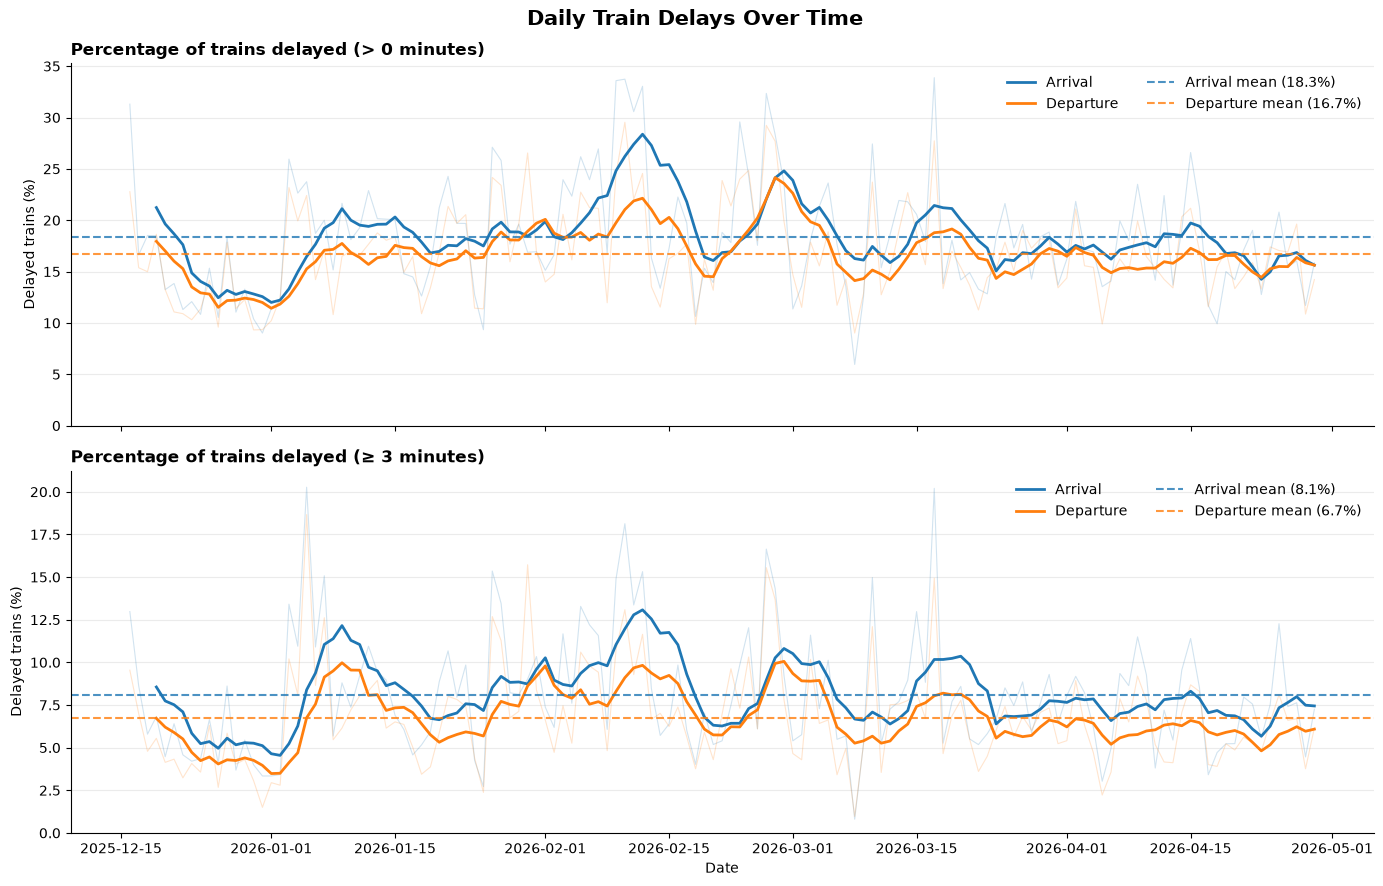

In [91]:
daily = train.groupby(train['Date'].dt.normalize()).agg(
    arrival_delayed=('arrival_delayed', 'mean'),
    departure_delayed=('departure_delayed', 'mean'),
    arrival_delayed_3=('arrival_delayed_3', 'mean'),
    departure_delayed_3=('departure_delayed_3', 'mean')
) * 100

# Smooth daily variation using a 7-day rolling average
rolling = daily.rolling(window=7, min_periods=4).mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

plots = [
    ('arrival_delayed', 'departure_delayed',
     'Percentage of trains delayed (> 0 minutes)'),
    ('arrival_delayed_3', 'departure_delayed_3',
     'Percentage of trains delayed (≥ 3 minutes)')
]

for ax, (arrival, departure, title) in zip(axes, plots):
    # Daily observations
    ax.plot(
        daily.index, daily[arrival],
        color='C0', alpha=0.2, linewidth=0.8
    )
    ax.plot(
        daily.index, daily[departure],
        color='C1', alpha=0.2, linewidth=0.8
    )

    # Seven-day rolling averages
    ax.plot(
        rolling.index, rolling[arrival],
        color='C0', linewidth=2, label='Arrival'
    )
    ax.plot(
        rolling.index, rolling[departure],
        color='C1', linewidth=2, label='Departure'
    )

    # Overall average
    ax.axhline(
        daily[arrival].mean(),
        color='C0', linestyle='--', alpha=0.8,
        label=f'Arrival mean ({daily[arrival].mean():.1f}%)'
    )
    ax.axhline(
        daily[departure].mean(),
        color='C1', linestyle='--', alpha=0.8,
        label=f'Departure mean ({daily[departure].mean():.1f}%)'
    )

    ax.set_title(title, loc='left', fontsize=12, fontweight='bold')
    ax.set_ylabel('Delayed trains (%)')
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(ncol=2, frameon=False, loc='upper right')

axes[-1].set_xlabel('Date')
fig.suptitle(
    'Daily Train Delays Over Time',
    fontsize=15, fontweight='bold'
)
fig.tight_layout()
plt.show()

##### 4.2 Spread of delay using box plots over time

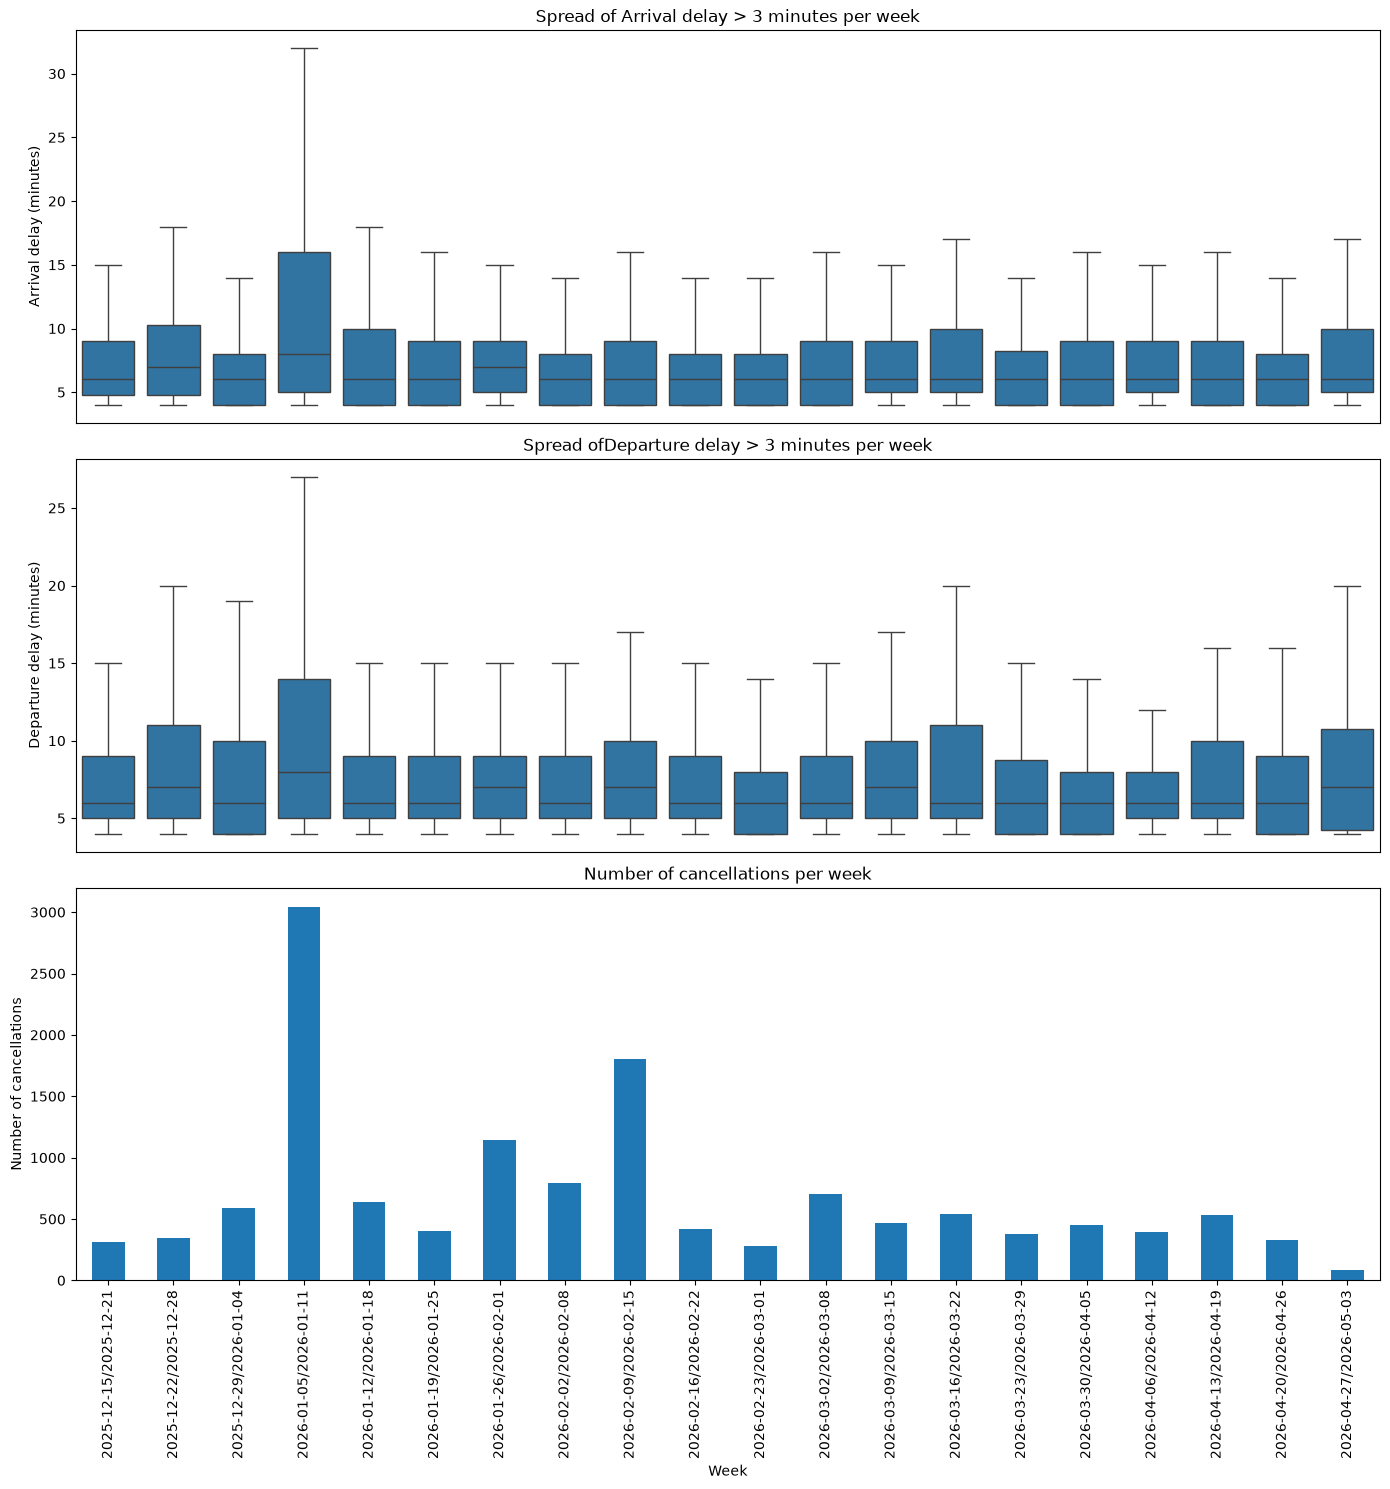

In [92]:
train['week'] = train['Date'].dt.to_period('W').astype(str)

# Filter delays greater than 3 minutes
train_arr_delayed = train[train['arr_delay'] > 3]
train_dep_delayed = train[train['dep_delay'] > 3]

# Count cancellations per week
weekly_cancelled = train.groupby('week')['cancelled'].sum()

fig, ax = plt.subplots(3, 1, figsize=(14, 15))

# Arrival delays
sns.boxplot(
    data=train_arr_delayed,
    x='week',
    y='arr_delay',
    showfliers=False,
    ax=ax[0]
)
ax[0].set_title('Spread of Arrival delay > 3 minutes per week')
ax[0].set_xlabel('')
ax[0].set_ylabel('Arrival delay (minutes)')
ax[0].tick_params(axis='x', bottom = False, labelbottom = False)

sns.boxplot(
    data=train_dep_delayed,
    x='week',
    y='dep_delay',
    showfliers=False,
    ax=ax[1]
)
ax[1].set_title('Spread ofDeparture delay > 3 minutes per week')
ax[1].set_xlabel('')
ax[1].set_ylabel('Departure delay (minutes)')
ax[1].tick_params(axis='x', bottom = False, labelbottom = False)

# Weekly cancellation counts
weekly_cancelled.plot(
    kind='bar',
    ax=ax[2]
)
ax[2].set_title('Number of cancellations per week')
ax[2].set_xlabel('Week')
ax[2].set_ylabel('Number of cancellations')

# Formatting
for a in ax:
    a.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

##### 4.3 Delays per hour

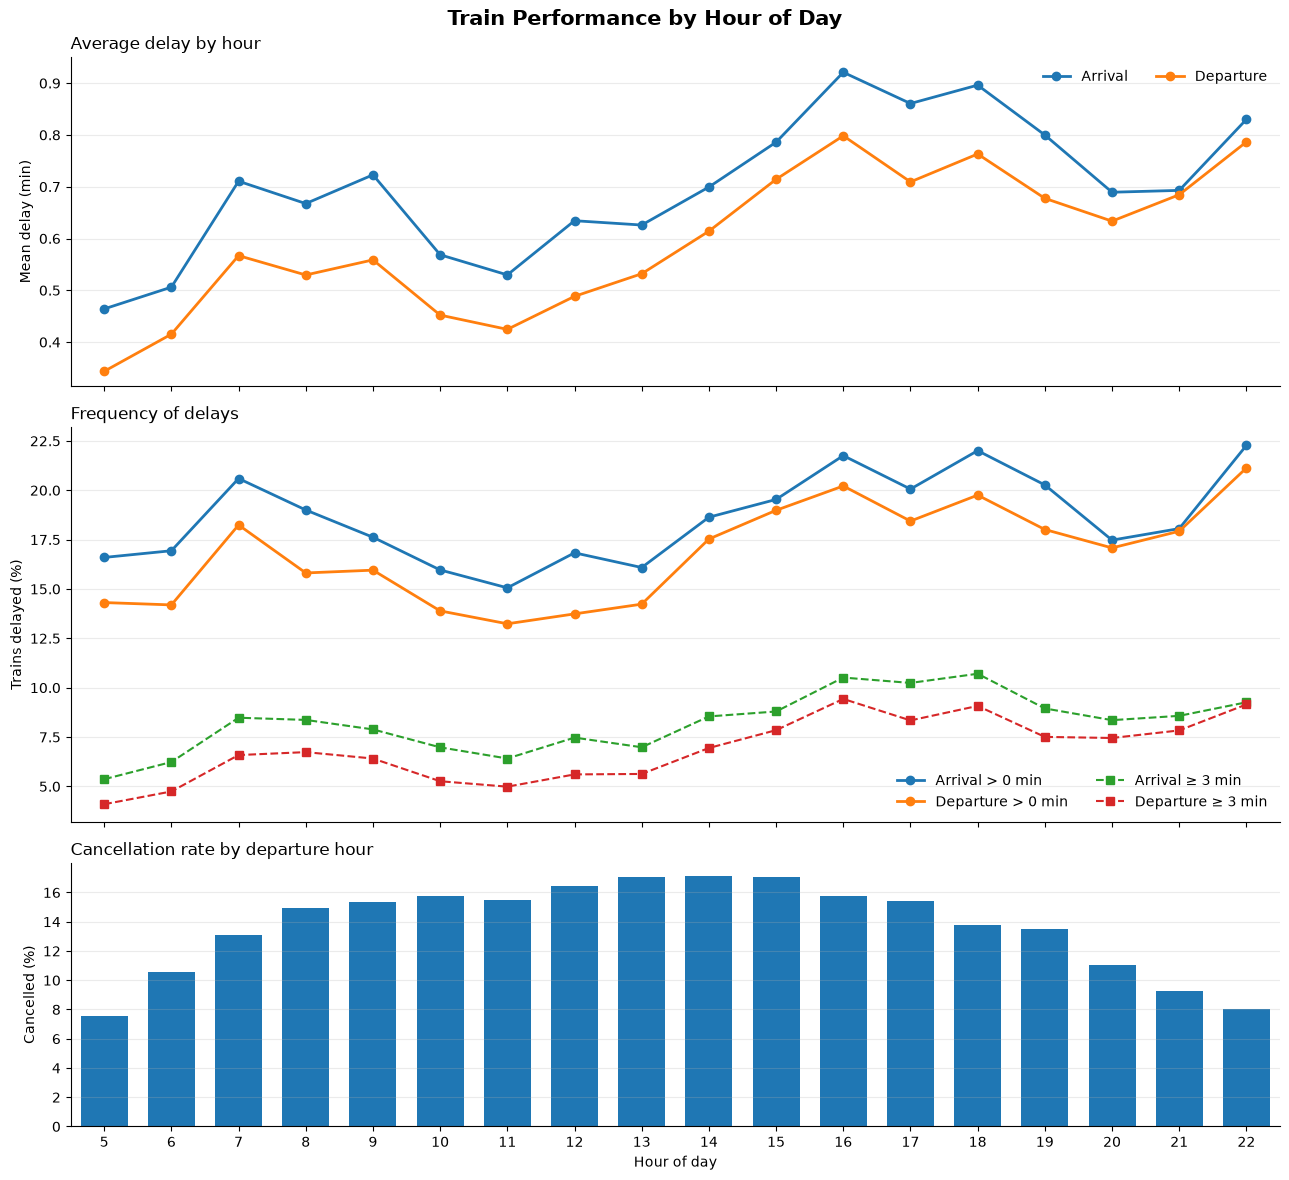

In [93]:
# Aggregate arrival statistics by arrival hour
arrival_hourly = train.groupby('arr_hour').agg(
    mean_delay=('arr_delay', 'mean'),
    median_delay=('arr_delay', 'median'),
    delayed=('arrival_delayed', 'mean'),
    delayed_3=('arrival_delayed_3', 'mean'),
    n_trains=('train_id', 'count')
)

# Aggregate departure statistics by departure hour
departure_hourly = train.groupby('dep_hour').agg(
    mean_delay=('dep_delay', 'mean'),
    median_delay=('dep_delay', 'median'),
    delayed=('departure_delayed', 'mean'),
    delayed_3=('departure_delayed_3', 'mean'),
    cancelled=('cancelled', 'mean'),
    n_trains=('train_id', 'count')
)

# Convert rates to percentages
for df in [arrival_hourly, departure_hourly]:
    for col in ['delayed', 'delayed_3']:
        df[col] *= 100

departure_hourly['cancelled'] *= 100

# Plot
fig, axes = plt.subplots(
    3, 1, figsize=(13, 12), sharex=True,
    gridspec_kw={'height_ratios': [1, 1.2, 0.8]}
)

# 1. Average delay by hour
axes[0].plot(
    arrival_hourly.index, arrival_hourly['mean_delay'],
    marker='o', linewidth=2, label='Arrival'
)
axes[0].plot(
    departure_hourly.index, departure_hourly['mean_delay'],
    marker='o', linewidth=2, label='Departure'
)
axes[0].set_ylabel('Mean delay (min)')
axes[0].set_title('Average delay by hour', loc='left')
axes[0].legend(frameon=False, ncol=2)
axes[0].grid(axis='y', alpha=0.25)

# 2. Percentage of trains delayed
axes[1].plot(
    arrival_hourly.index, arrival_hourly['delayed'],
    marker='o', linewidth=2, label='Arrival > 0 min'
)
axes[1].plot(
    departure_hourly.index, departure_hourly['delayed'],
    marker='o', linewidth=2, label='Departure > 0 min'
)
axes[1].plot(
    arrival_hourly.index, arrival_hourly['delayed_3'],
    marker='s', linestyle='--', label='Arrival ≥ 3 min'
)
axes[1].plot(
    departure_hourly.index, departure_hourly['delayed_3'],
    marker='s', linestyle='--', label='Departure ≥ 3 min'
)
axes[1].set_ylabel('Trains delayed (%)')
axes[1].set_title('Frequency of delays', loc='left')
axes[1].legend(frameon=False, ncol=2)
axes[1].grid(axis='y', alpha=0.25)

# 3. Cancellation rate by departure hour
axes[2].bar(
    departure_hourly.index, departure_hourly['cancelled'],
    width=0.7
)
axes[2].set_ylabel('Cancelled (%)')
axes[2].set_title('Cancellation rate by departure hour', loc='left')
axes[2].grid(axis='y', alpha=0.25)

# Formatting
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_xlim(4.5, 22.5)
    ax.set_xticks(range(5, 23))

axes[2].set_xlabel('Hour of day')

fig.suptitle(
    'Train Performance by Hour of Day',
    fontsize=15, fontweight='bold'
)
fig.tight_layout()
plt.show()


Can be observed most delays occur in the morning peak in hour 07:00 - 08:00 and the evening peak in hour 19:00 - 20:00
The percentage of delayed trains are biggest in the evening peak, in the morning only from 07:00 - 08:00:
- from 16:00 - 20:00 the mean percentage is above 22%
- from 16:00 - 20:00 the mean percentage of delays above 3 minutes is above 11%

Cancellations are highest around 13:00-15:00 at 16.2% and lowest in the early mornings and evenings.

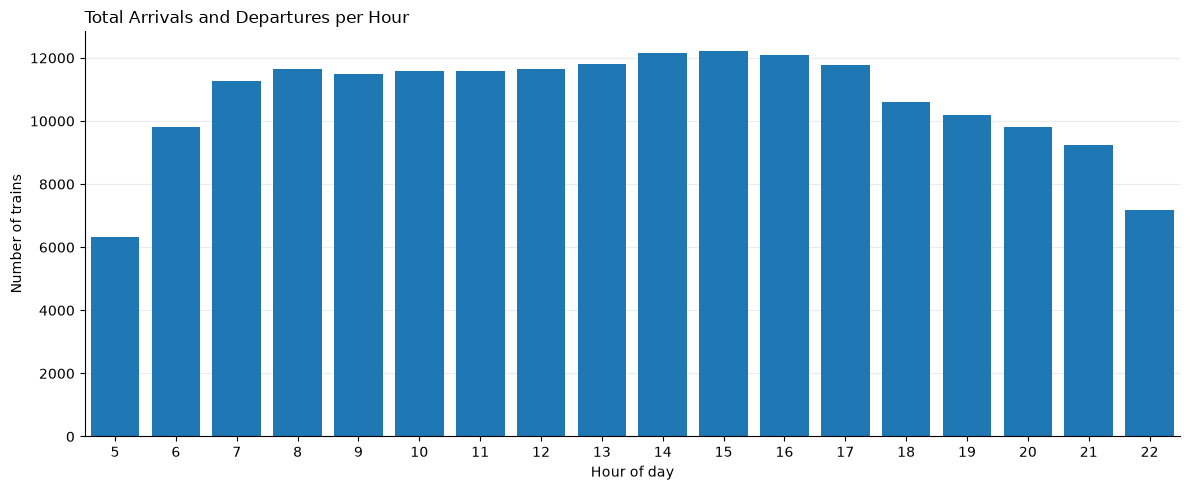

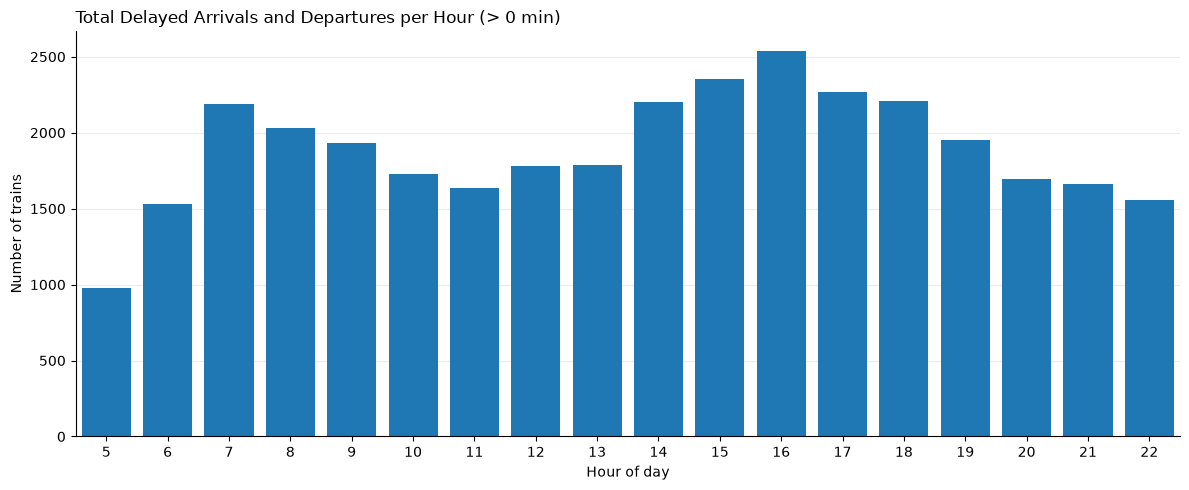

In [94]:

# ---------------------------------------------------------
# 1. Total number of arrivals and departures per hour
# ---------------------------------------------------------

arrival_counts = train.groupby('arr_hour')['train_id'].count()
departure_counts = train.groupby('dep_hour')['train_id'].count()

total_counts = arrival_counts.add(
    departure_counts, fill_value=0
).sort_index()

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(total_counts.index, total_counts.values, width=0.8)

ax.set_xlabel('Hour of day')
ax.set_ylabel('Number of trains')
ax.set_title('Total Arrivals and Departures per Hour', loc='left')
ax.set_xticks(range(5, 23))
ax.set_xlim(4.5, 22.5)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------
# 2. Total number of delayed arrivals and departures per hour
# ---------------------------------------------------------

arrival_delayed = (
    train.loc[train['arr_delay'] > 0]
    .groupby('arr_hour')['train_id']
    .count()
)

departure_delayed = (
    train.loc[train['dep_delay'] > 0]
    .groupby('dep_hour')['train_id']
    .count()
)

total_delayed = arrival_delayed.add(
    departure_delayed, fill_value=0
).sort_index()

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(total_delayed.index, total_delayed.values, width=0.8)

ax.set_xlabel('Hour of day')
ax.set_ylabel('Number of trains')
ax.set_title('Total Delayed Arrivals and Departures per Hour (> 0 min)',
             loc='left')
ax.set_xticks(range(5, 23))
ax.set_xlim(4.5, 22.5)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()


##### 4.4 Punctuality indicator

Initialize **train punctual** as dataset without the cancellations
- A train is formally punctual if it is within 180 seconds of original time (but we define both)
- Define punctuality as a trivial: (# of on-time events / total scheduled events) * 100
- Split in arrival and departure punctuality
- Define total punctuality.
For punctuality only consider trains which ran, not cancelled

In [95]:
train_punctual = train[train['cancelled'] == False] # Keeping only non-cancelled trains for punctuality analysis

train_punctual['delay_status'] = train_punctual['arr_delay'].apply(lambda x: 'On time' if x <= 0 else ('Delayed' if x <= 3 else 'Significantly Delayed'))
train_punctual['arr_punctual'] = train_punctual['arr_delay'] < 3

train_punctual["dep_delay_status"] = train_punctual["dep_delay"].apply(lambda x: "On time" if x <= 0 else ("Delayed" if x < 3 else "Significantly Delayed"))
train_punctual["dep_punctual"] = train_punctual["dep_delay"] < 3

train_punctual.head()

,Date,train_id,Type,scheduled_arrival,actual_arrival,scheduled_departure,actual_departure,arr_delay,dep_delay,arr_cancelled,...,arrival_delayed,departure_delayed,arrival_delayed_3,departure_delayed_3,cancelled,week,delay_status,arr_punctual,dep_delay_status,dep_punctual
0,2025-12-16,157463214,Intercity,05:06,05:06,05:09,05:09,0.0,0.0,False,...,False,False,False,False,False,2025-12-15/2025-12-21,On time,True,On time,True
1,2025-12-16,157462484,Intercity,05:09,05:09,05:13,05:13,0.0,0.0,False,...,False,False,False,False,False,2025-12-15/2025-12-21,On time,True,On time,True
2,2025-12-16,157462757,Sprinter,05:11,05:11,05:14,05:14,0.0,0.0,False,...,False,False,False,False,False,2025-12-15/2025-12-21,On time,True,On time,True
3,2025-12-16,157462872,Intercity,05:07,05:11,05:09,05:13,4.0,4.0,False,...,True,True,True,True,False,2025-12-15/2025-12-21,Significantly Delayed,False,Significantly Delayed,False
4,2025-12-16,157464386,Sprinter,05:11,05:11,05:14,05:14,0.0,0.0,False,...,False,False,False,False,False,2025-12-15/2025-12-21,On time,True,On time,True


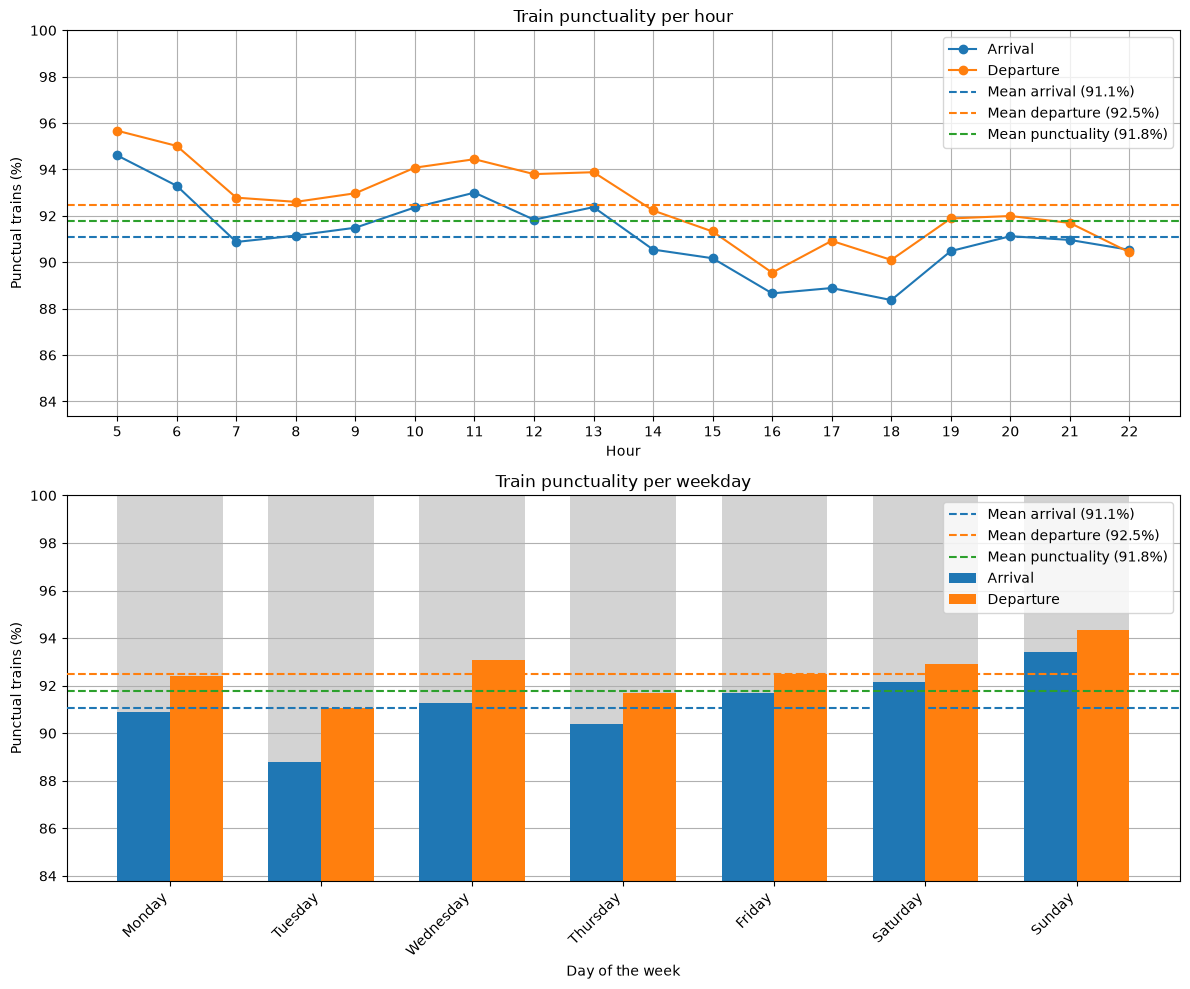

In [96]:
fig, ax = plt.subplots(2, 1, figsize=(12, 10))

arr_mean = train_punctual["arr_punctual"].mean() * 100
dep_mean = train_punctual["dep_punctual"].mean() * 100
tot_mean = (
    train_punctual["arr_punctual"].sum()
    + train_punctual["dep_punctual"].sum()
) / (
    train_punctual["arr_punctual"].count()
    + train_punctual["dep_punctual"].count()
) * 100


# Plot 1: Punctuality per hour
arr_punctual = train_punctual.groupby("arr_hour")["arr_punctual"].mean() * 100
dep_punctual = train_punctual.groupby("dep_hour")["dep_punctual"].mean() * 100

ax[0].plot(arr_punctual.index, arr_punctual.values,
           marker="o", label="Arrival")
ax[0].plot(dep_punctual.index, dep_punctual.values,
           marker="o", label="Departure")

ax[0].axhline(arr_mean, linestyle="--", color="C0", label=f"Mean arrival ({arr_mean:.1f}%)")
ax[0].axhline(dep_mean, linestyle="--", color="C1",label=f"Mean departure ({dep_mean:.1f}%)")
ax[0].axhline(tot_mean, linestyle="--", color="C2",label=f"Mean punctuality ({tot_mean:.1f}%)")

ax[0].set_xlabel("Hour")
ax[0].set_ylabel("Punctual trains (%)")
ax[0].set_title("Train punctuality per hour")
ax[0].set_xticks(range(5, 23))
ax[0].set_ylim(min(arr_punctual.min(), dep_punctual.min()) - 5, 100)
ax[0].grid()
ax[0].legend()


# Plot 2: Punctuality per weekday
train_punctual["Date"] = pd.to_datetime(train_punctual["Date"])
train_punctual["weekday"] = train_punctual["Date"].dt.day_name()

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"]

weekly = train_punctual.groupby("weekday")[
    ["arr_punctual", "dep_punctual"]
].mean().mul(100).reindex(weekday_order)

x = range(len(weekday_order))
width = 0.35

# Grey areas above each bar, up to 100%
for i, col in enumerate(["arr_punctual", "dep_punctual"]):
    positions = [j + (i - 0.5) * width for j in x]
    values = weekly[col].values

    ax[1].bar(
        positions, 100 - values, width,
        bottom=values, color="lightgrey",
        edgecolor="none", zorder=1
    )

for i, (col, label) in enumerate([
    ("arr_punctual", "Arrival"),
    ("dep_punctual", "Departure")
]):
    positions = [j + (i - 0.5) * width for j in x]
    values = weekly[col].values

    ax[1].bar(
        positions, values - 80, width,
        bottom=80, label=label, zorder=2
    )

# Overall mean lines
ax[1].axhline(arr_mean, linestyle="--", color="C0", label=f"Mean arrival ({arr_mean:.1f}%)", zorder=3)
ax[1].axhline(dep_mean, linestyle="--", color="C1", label=f"Mean departure ({dep_mean:.1f}%)", zorder=3)
ax[1].axhline(tot_mean, linestyle="--", color="C2",label=f"Mean punctuality ({tot_mean:.1f}%)")

ax[1].set_xlabel("Day of the week")
ax[1].set_ylabel("Punctual trains (%)")
ax[1].set_title("Train punctuality per weekday")
ax[1].set_xticks(list(x))
ax[1].set_xticklabels(weekday_order, rotation=45, ha="right")
ax[1].set_ylim(min(weekly["arr_punctual"].min(), weekly["dep_punctual"].min()) - 5, 100)
ax[1].grid(axis="y", zorder=0)
ax[1].legend()

plt.tight_layout()
plt.show()

Similar to cancellation conditions of punctuality on both conditions:

Overall punctuality is assessed by determining the percentage of trains that meet the punctuality threshold at both departure and arrival. This indicator provides a combined measure of operational performance, as a train is considered punctual only when both conditions are satisfied. Comparing this value with arrival and departure punctuality separately can help identify whether delays are recovered or whether trains lose punctuality during the journey:

In [97]:
total_punctuality = tot_mean = (
    train_punctual["arr_punctual"].sum()
    + train_punctual["dep_punctual"].sum()
) / (
    train_punctual["arr_punctual"].count()
    + train_punctual["dep_punctual"].count()
) * 100
print(f"Trains punctual at both arrival and departure:  {total_punctuality:.2f}%")
print(f"Trains punctual at arrival:                     {arr_mean:.2f}%")
print(f"Trains punctual at departure:                   {dep_mean:.2f}%")

Trains punctual at both arrival and departure:  91.78%
Trains punctual at arrival:                     91.08%
Trains punctual at departure:                   92.48%


Train punctuality of departures seem consistenly higher than of arrivals, both per hour as per weekday analysed in the dataset. The mean values confirm this. 
- This is cause for investigation of delay absorption of utrecht centraal next.

First do a classification of lost and found punctuality:

In [98]:
categories = []

for i, row in train_punctual.iterrows():
    if row['dep_punctual'] and row['arr_punctual']:
        categories.append('Punctual both')
    elif row['dep_punctual'] and not row['arr_punctual']:
        categories.append('Punctual departure, delayed arrival')
    elif not row['dep_punctual'] and row['arr_punctual']:
        categories.append('Delayed departure, punctual arrival')
    else:
        categories.append('Delayed both')

train_punctual["punctual_cat"] = categories

category_summary = train_punctual["punctual_cat"].value_counts()

category_summary = pd.DataFrame({
    "Number of trains": category_summary,
    "Percentage (%)": (category_summary / len(train_punctual) * 100).round(1)
})

category_summary

,Number of trains,Percentage (%)
punctual_cat,,
Punctual both,73756,89.3
Delayed both,4748,5.7
"Punctual departure, delayed arrival",2621,3.2
"Delayed departure, punctual arrival",1466,1.8


In [99]:
category_summary = train_punctual["punctual_cat"].value_counts()

delayed_summary = category_summary.drop("Punctual both")

delayed_summary = pd.DataFrame({
    "Number of trains": delayed_summary,
    "Percentage (%)": (delayed_summary / delayed_summary.sum() * 100).round(1)
})

delayed_summary

,Number of trains,Percentage (%)
punctual_cat,,
Delayed both,4748,53.7
"Punctual departure, delayed arrival",2621,29.7
"Delayed departure, punctual arrival",1466,16.6


Of the 12.1% delayed, 59% is delayed at both arrival and departure; wherares the percentage of absorbed delay is bigger than increased or new delay at utrecht centraal.

##### 4.5 Delays accumulated or dissolved at Utrecht Centraal

Now to calculate an absorption factor, as some trains are non-punctual at arrival, and punctual at arrival and vice versa.

The delay change incidates the direct delay absorption per train:
- Delay change = arrival delay - departure delay
- Delay change < 0: Delays accumulated
- Delay change = 0: No change (either no delay or no change (2 datasets analysed))
- Delay change > 0: Delays dissolved/absorbed

Absorption factor equals the (departure delay - arrrival delay) / departure delay

In [100]:
# Mean delay change for ALL non-cancelled trains
all_trains = train_punctual.dropna(
    subset=['arr_delay', 'dep_delay']
).copy()

all_trains['delay_change'] = (
    all_trains['dep_delay'] - all_trains['arr_delay']
)

mean_delay_change = all_trains['delay_change'].mean().round(1)

if mean_delay_change > 0:
    print(f"The mean train delay change in total set equals: {mean_delay_change} minutes (delays absorbed)")
elif mean_delay_change == 0:
    print(f"The mean train delay change in total set equals: {mean_delay_change} minutes (no change)")
else:
    print(f"The mean train delay change in total set equals: {mean_delay_change} minutes (delays accumulated)")

print("")

# Analysis of trains arriving late
delay_comparison = all_trains[
    all_trains['arr_delay'] > 0
].copy()

delay_comparison['delay_change'] = (
    delay_comparison['dep_delay'] - delay_comparison['arr_delay']
)

print(
    f"The maximum delay accumulated is {delay_comparison['delay_change'].min()} minutes "
    f"and the maximum delay absorbed is {delay_comparison['delay_change'].max()} minutes"
)

# Net percentage of arrival delay recovered among late-arriving trains
total_arr_delay = delay_comparison['arr_delay'].sum()
total_dep_delay = delay_comparison['dep_delay'].sum()

overall_absorption = (
    (total_arr_delay - total_dep_delay) / total_arr_delay * 100
    if total_arr_delay > 0 else float('nan')
)

print(f"Overall delay absorption: {overall_absorption:.2f}%")

# Mean net delay recovery across late-arriving trains
overall_net_delay_change = delay_comparison['delay_change'].mean()

print(f"Overall net delay change (late-arriving trains): {overall_net_delay_change:.2f} minutes per train")

# Late-arrival delay absorption (same population as overall_absorption here)
late_absorption = overall_absorption

print(f"Late arrival delay absorption: {late_absorption:.2f}%")

The mean train delay change in total set equals: -0.1 minutes (delays accumulated)

The maximum delay accumulated is -8.0 minutes and the maximum delay absorbed is 27.0 minutes
Overall delay absorption: 29.02%
Overall net delay change (late-arriving trains): -1.04 minutes per train
Late arrival delay absorption: 29.02%


An overall delay absorption of 10.9% means that the total departure delay across all trains is 10.9% lower than the total arrival delay in Utrecht Centraal:
- For every 100 minutes of arrival delay, there will be 89.1 minutes of total departure delay

28.4% of existing arrival delay is absorbed, calculated across trains that arrived late. 
- A train arriving late absorbs more delay than a train arriving without delay.
- Delay accumulation among other trains partly offset recovery of existing delays when anaylsing the 10.9%

Discard of absorption for all trains, only viewing net delay change (sum(departure delay) - sum(arrival_delay)) / number of trains.
- Positive net delay change means trains leave with more delay than they arrived with. Negative means they recover delay

In [101]:
total_arr_delay = delay_comparison["arr_delay"].sum()
total_dep_delay = delay_comparison["dep_delay"].sum()

net_delay_change = total_dep_delay - total_arr_delay

if net_delay_change < 0:
    print(f"Over the period: The total departure delay was {abs(net_delay_change):.1f} minutes lower than the total arrival delay")
    print(f"Per day:         The total departure delay was {abs(net_delay_change/train['Date'].nunique()):.1f} minutes lower than the total arrival delay")
else:
    print(f"The total departure delay was {net_delay_change:.2f} minutes higher than the total arrival delay over the period")

Over the period: The total departure delay was 17504.0 minutes lower than the total arrival delay
Per day:         The total departure delay was 129.7 minutes lower than the total arrival delay


PER TRAIN

Mean net delay change (all running trains): -0.08 min/train
Mean net delay change (included trains): -0.08 min/train
Overall delay absorption: 11.19%
Late-arrival delay absorption: 40.88%


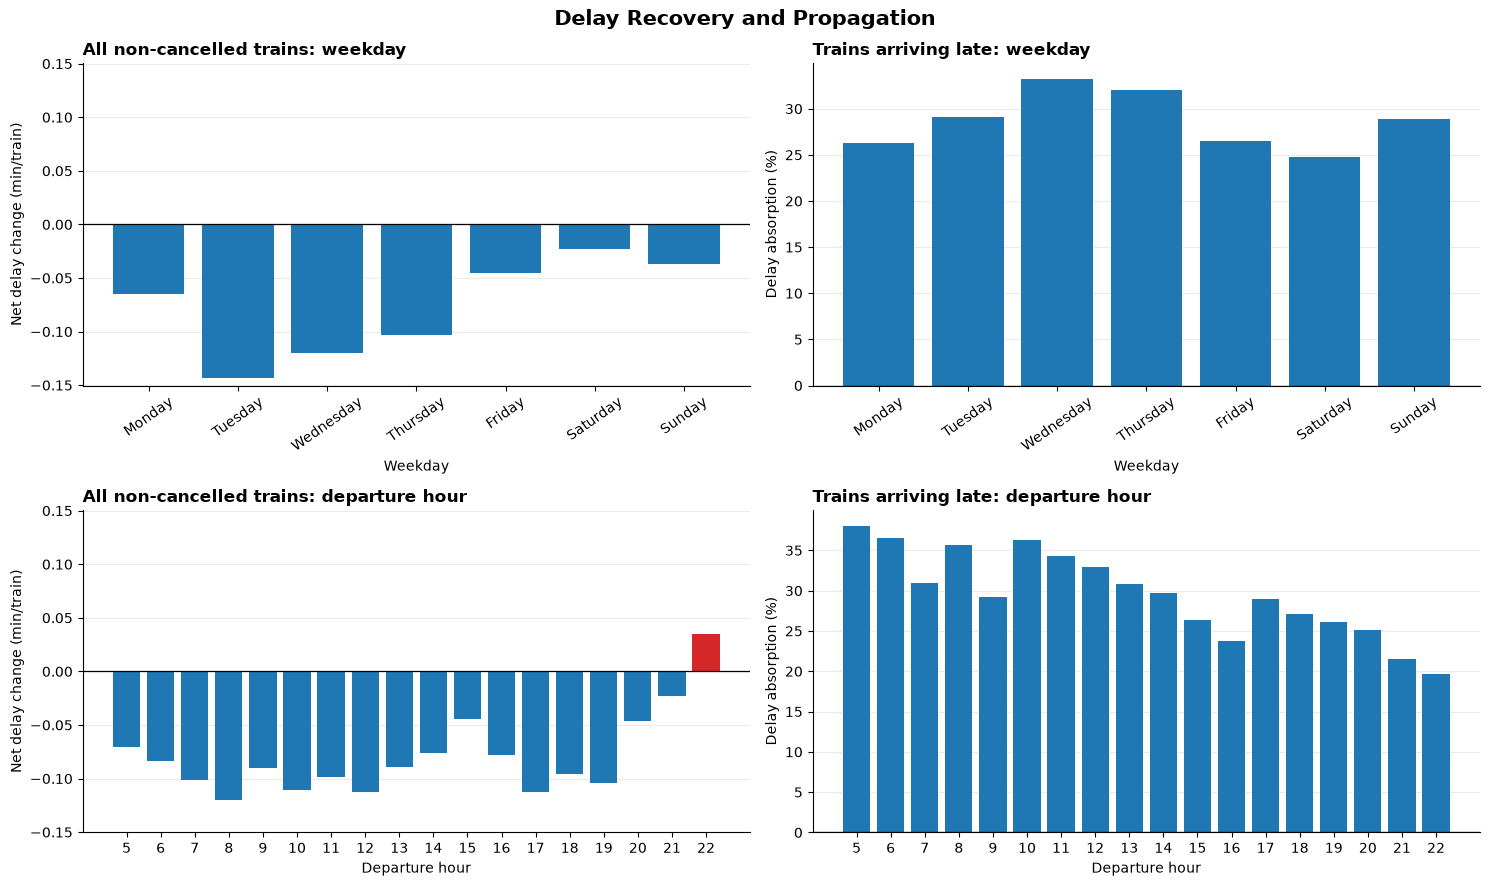

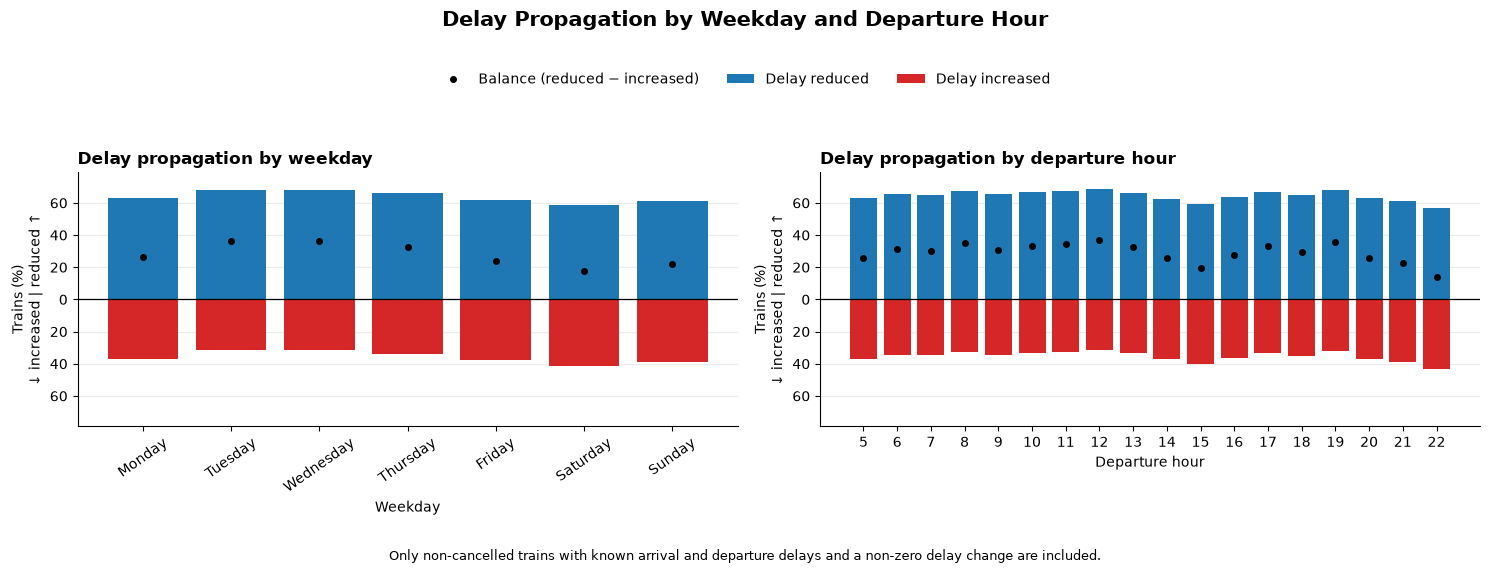

In [102]:
punctual = train.loc[~train['cancelled'].fillna(False)].copy()

comp = punctual.dropna(subset=['arr_delay', 'dep_delay']).copy()
# Positive delay_change = delay reduced
# Negative delay_change = delay increased
comp['delay_change'] = comp['dep_delay'] - comp['arr_delay']
comp['weekday'] = comp['Date'].dt.day_name()

late = comp[comp['arr_delay'] > 0].copy()

# Classify delay propagation using 3- and 1-minute thresholds
for threshold in (3, 1):
    comp[f'delay_propagation_{threshold}min'] = np.select(
        [
            comp['delay_change'] > threshold,
            comp['delay_change'] < -threshold
        ],
        ['Delay reduced', 'Delay increased'],
        default='Unchanged delay'
    )

# Summary metrics
mean_all = (punctual['dep_delay'] - punctual['arr_delay']).mean()
mean_selected = (comp['dep_delay'] - comp['arr_delay']).mean()

arr_sum = comp['arr_delay'].sum()
dep_sum = comp['dep_delay'].sum()

net_per_train = (dep_sum - arr_sum) / len(comp) if len(comp) else np.nan
overall_absorption = (
    (arr_sum - dep_sum) / arr_sum * 100 if arr_sum > 0 else np.nan
)

late_arr_sum = late['arr_delay'].sum()
late_dep_sum = late['dep_delay'].sum()
late_absorption = (
    (late_arr_sum - late_dep_sum) / late_dep_sum * 100
    if late_arr_sum > 0 else np.nan
)

print(f'Mean net delay change (all running trains): {mean_all:.2f} min/train')
print(f'Mean net delay change (included trains): {mean_selected:.2f} min/train')
print(f'Overall delay absorption: {overall_absorption:.2f}%')
print(f'Late-arrival delay absorption: {late_absorption:.2f}%')


# ---------------------------------------------------------------------
# Figure 1: Net delay change and delay absorption
# ---------------------------------------------------------------------
order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
]
hours = list(range(5, 23))

def absorption_pct(x):
    arr = x['arr_delay'].sum()
    return (arr - x['dep_delay'].sum()) / arr * 100 if arr > 0 else np.nan

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for col, subset in enumerate([comp, late]):

    if col == 0:
        # Net change = departure delay - arrival delay (negative = reduced)
        weekday = (
            subset.groupby('weekday')
            .apply(lambda x: (x['dep_delay'] - x['arr_delay']).mean())
            .reindex(order)
        )
        hour = (
            subset.groupby('dep_hour')
            .apply(lambda x: (x['dep_delay'] - x['arr_delay']).mean())
            .reindex(hours)
        )
        ylabel = 'Net delay change (min/train)'
        title = 'All non-cancelled trains'
    else:
        weekday = subset.groupby('weekday').apply(absorption_pct).reindex(order)
        hour = subset.groupby('dep_hour').apply(absorption_pct).reindex(hours)
        ylabel = 'Delay absorption (%)'
        title = 'Trains arriving late'

    for row, (values, xlabel) in enumerate([
        (weekday, 'Weekday'),
        (hour, 'Departure hour')
    ]):
        ax = axes[row, col]
        values = values.astype(float)

        # Blue = delay reduced, red = delay increased, in all panels
        if col == 0:
            colours = ['C0' if v < 0 else 'C3' for v in values.fillna(0)]
        else:
            colours = ['C0' if v > 0 else 'C3' if v < 0 else 'lightgrey'
                       for v in values.fillna(0)]

        ax.bar(values.index.astype(str), values, color=colours)
        ax.axhline(0, color='black', linewidth=0.9)
        ax.set_ylabel(ylabel)
        ax.set_xlabel(xlabel)
        ax.set_title(f'{title}: {xlabel.lower()}',
                     loc='left', fontweight='bold')
        ax.grid(axis='y', alpha=0.25)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)

        if row == 0:
            ax.tick_params(axis='x', rotation=35)

# Same y-range for both rows of the left column (autoscaled, symmetric)
lim = max(abs(a) for ax in axes[:, 0] for a in ax.get_ylim())
for ax in axes[:, 0]:
    ax.set_ylim(-lim, lim)

fig.suptitle('Delay Recovery and Propagation', fontsize=15, fontweight='bold')
fig.tight_layout()
plt.show()


groups = [
        ('weekday', order, 'Weekday'),
        ('dep_hour', hours, 'Departure hour'),
    ]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # Exclude trains with no delay change
changed = comp.loc[
        comp['arr_delay'] != comp['dep_delay']
    ].copy()

    # Classify any reduction or increase in delay (> 0 minutes)
changed['delay_propagation'] = np.where(
        changed['arr_delay'] > changed['dep_delay'],
        'Delay reduced',
        'Delay increased'
    )

for ax, (g, idx, xlabel) in zip(axes, groups):

        tab = (
            changed.groupby([g, 'delay_propagation'], observed=False)
            .size()
            .unstack(fill_value=0)
            .reindex(idx, fill_value=0)
            .reindex(
                columns=['Delay reduced', 'Delay increased'],
                fill_value=0
            )
        )

        pct = tab.div(
            tab.sum(axis=1).replace(0, np.nan),
            axis=0
        ) * 100

        reduced = pct['Delay reduced'].fillna(0).to_numpy()
        increased = pct['Delay increased'].fillna(0).to_numpy()

        x = np.arange(len(idx))

        ax.bar(
            x, reduced, width=0.8,
            color='C0', label='Delay reduced'
        )
        ax.bar(
            x, -increased, width=0.8,
            color='C3', label='Delay increased'
        )
        ax.plot(
            x, reduced - increased,
            'o', color='black', markersize=4,
            label='Balance (reduced − increased)'
        )
        ax.axhline(0, color='black', linewidth=0.9)

        ax.set_xticks(x)
        ax.set_xticklabels(
            [str(v) for v in idx],
            rotation=35 if g == 'weekday' else 0
        )

        max_val = max(
            np.max(reduced, initial=0),
            np.max(increased, initial=0)
        )
        limit = max(5, np.ceil(max_val * 1.15))
        ax.set_ylim(-limit, limit)

        ax.yaxis.set_major_formatter(
            FuncFormatter(lambda v, _: f'{abs(v):.0f}')
        )
        ax.set_xlabel(xlabel)
        ax.set_ylabel('Trains (%)\n↓ increased | reduced ↑')
        ax.set_title(
            f'Delay propagation by {xlabel.lower()}',
            loc='left', fontweight='bold'
        )
        ax.grid(axis='y', alpha=0.25)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
        handles, labels,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.98),
        ncol=3,
        frameon=False
    )

fig.suptitle(
        'Delay Propagation by Weekday and Departure Hour',
        fontsize=15, fontweight='bold',
        y=1.08
    )

fig.text(
        0.5, -0.02,
        'Only non-cancelled trains with known arrival and departure delays '
        'and a non-zero delay change are included.',
        ha='center', fontsize=9
    )

fig.tight_layout(rect=(0, 0.04, 1, 0.90))
plt.show()

Delays seem to absorb better in the morning than in the afternoon. Also delays absorb best Tuesday, Wednesday and Thursday

In [103]:
for train_type in ["Intercity", "Sprinter"]:
    subset = delay_comparison[
        (delay_comparison["Type"] == train_type)
        & (delay_comparison["arr_delay"] > 0)
    ]

    absorption = (
        (subset["arr_delay"].sum() - subset["dep_delay"].sum())
        / subset["arr_delay"].sum()
        * 100
    )

    print(f"{train_type} absorption: {absorption:.2f}%")

Intercity absorption: 27.38%
Sprinter absorption: 34.22%


Smaller delays seem more easily absorbed than larger delays

##### 4.6 Heatmap correlation of delays and cancellations

Dwell time and delay absorption
- What is the relationship between the amount of dwell time and delay absorption?

-100% is strong delay accumulation, 100% is strong delay absorption. Found here that logic for absorption is wrong for all trains as no penalisation for small delays (0-1 minutes lets say). Ammended.

Positive means accumulated delay, negative means absorbed delay.

Trains remaining: 22,369
Valid dwell times: 22,369

Dwell-time distribution:
dwell_bin
0-1       911
2        2517
3        6613
4        3485
5        4574
6-7      3738
8-9       297
10-14     165
15+        69
Name: count, dtype: int64

Late-arriving trains: 16865


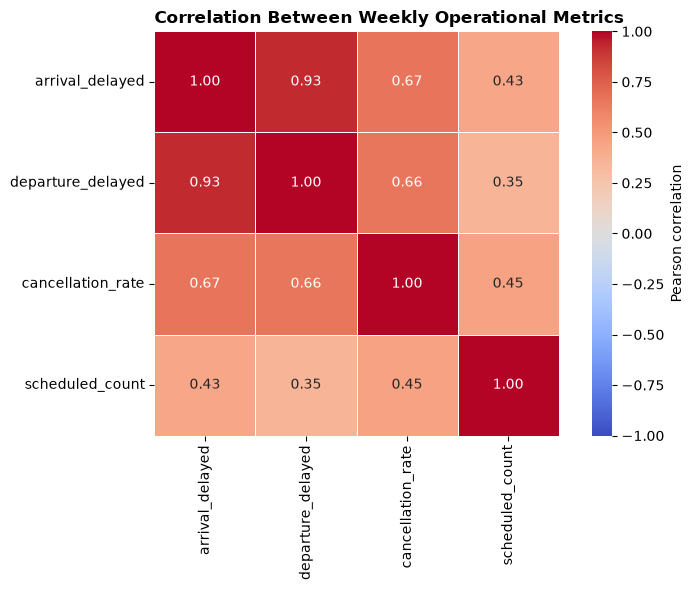

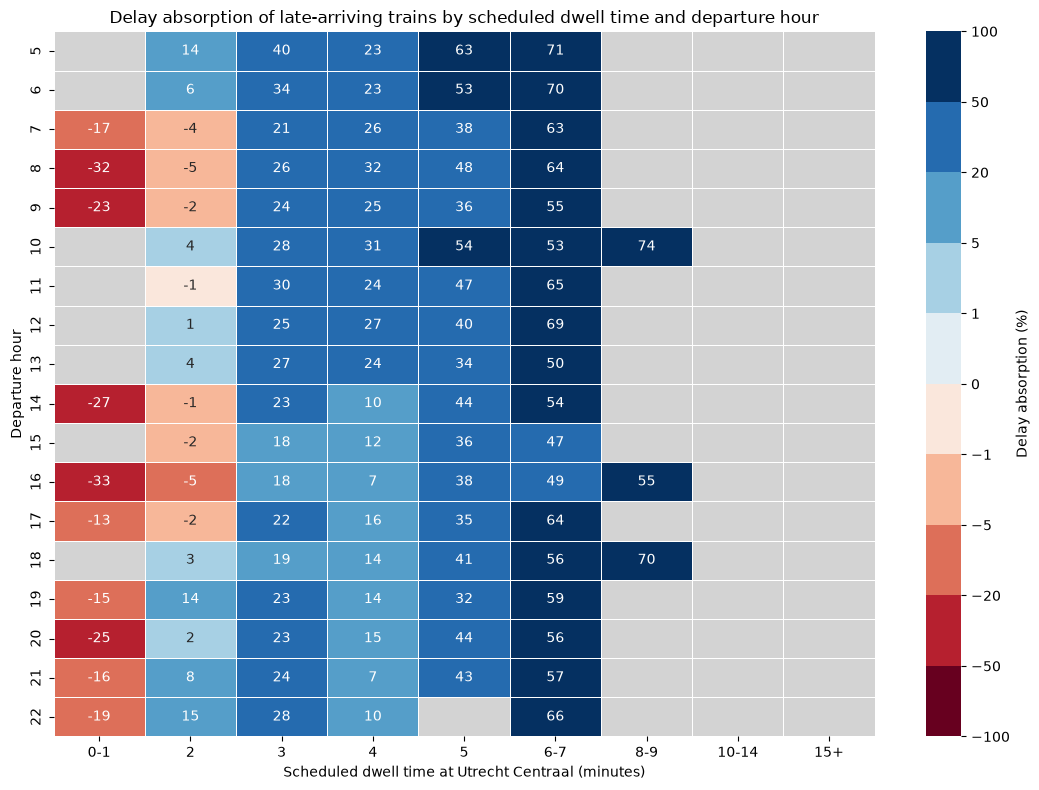

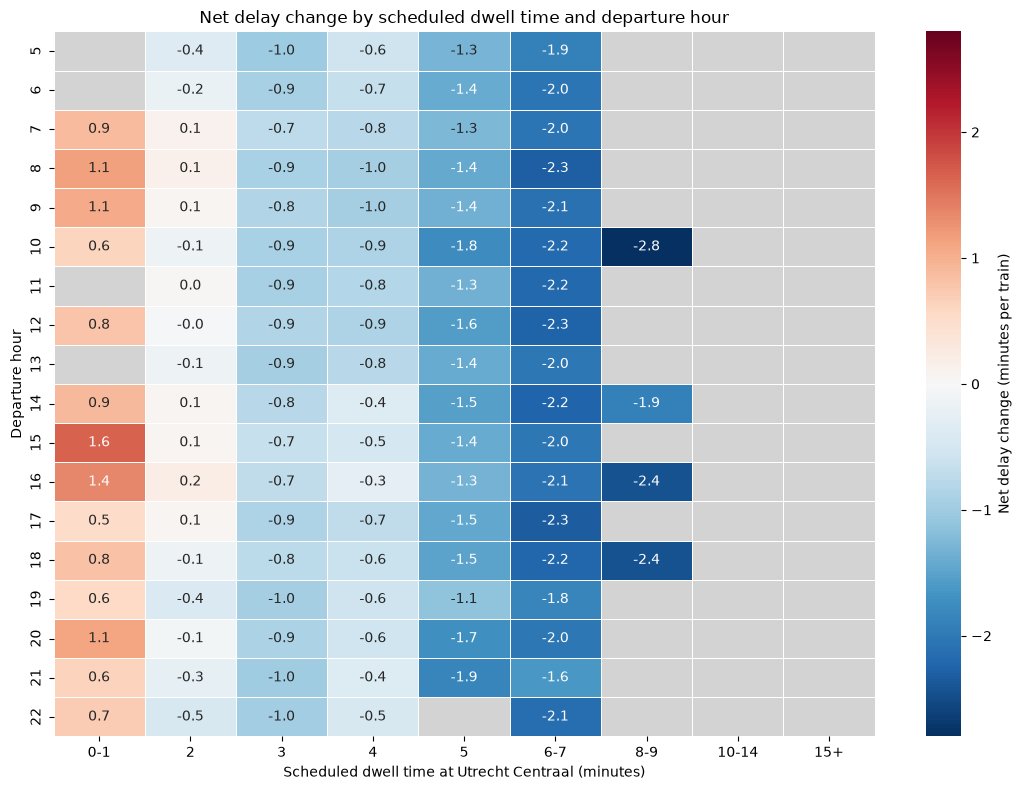

NameError: name 'heat_late' is not defined

In [104]:
punctual = train.loc[~train['cancelled'].fillna(False)].copy()

punctual['Date'] = pd.to_datetime(punctual['Date'], errors='coerce')

punctual['arr_punctual'] = punctual['arr_delay'] < 3
punctual['dep_punctual'] = punctual['dep_delay'] < 3
punctual['both_punctual'] = (
    punctual['arr_punctual'] & punctual['dep_punctual']
)

punctual['weekday'] = punctual['Date'].dt.day_name()

# Use trains with valid arrival and departure delay data
comp = punctual.dropna(
    subset=['arr_delay', 'dep_delay', 'Date', 'train_id']
).copy()

# Exclude trains with zero delay at both arrival and departure
comp = comp.loc[
    ~((comp['arr_delay'] == 0) & (comp['dep_delay'] == 0))
].copy()

# Positive = delay recovery; negative = delay accumulation
comp['delay_change'] = comp['arr_delay'] - comp['dep_delay']

# ---------------------------------------------------------------------
# 2. Calculate scheduled dwell time (FIXED)
# ---------------------------------------------------------------------

def clock_minutes(series):
    """Convert HH:MM or HH:MM:SS strings to minutes after midnight."""
    values = series.astype(str).str.strip()

    # Handle columns stored as datetime-like strings as well
    parsed = pd.to_datetime(values, format='%H:%M:%S', errors='coerce')
    missing = parsed.isna()
    parsed.loc[missing] = pd.to_datetime(
        values.loc[missing], format='%H:%M', errors='coerce'
    )

    # Handle actual datetime objects or full timestamp strings
    missing = parsed.isna()
    if missing.any():
        fallback = pd.to_datetime(values.loc[missing], errors='coerce')
        parsed.loc[missing] = fallback

    return (
        parsed.dt.hour * 60
        + parsed.dt.minute
        + parsed.dt.second / 60
    )


arr_minutes = clock_minutes(comp['scheduled_arrival'])
dep_minutes = clock_minutes(comp['scheduled_departure'])

# Calculate dwell time, including overnight crossings
comp['dwell_time'] = (dep_minutes - arr_minutes) % 1440

# Mark invalid or implausibly long dwell times as missing
comp.loc[
    arr_minutes.isna()
    | dep_minutes.isna()
    | (comp['dwell_time'] > 180),
    'dwell_time'
] = np.nan

dwell_bins = [0, 2, 3, 4, 5, 6, 8, 10, 15, np.inf]
dwell_labels = [
    '0-1', '2', '3', '4', '5', '6-7',
    '8-9', '10-14', '15+'
]

comp['dwell_bin'] = pd.cut(
    comp['dwell_time'],
    bins=dwell_bins,
    labels=dwell_labels,
    right=False
)

comp['dep_hour'] = pd.to_numeric(comp['dep_hour'], errors='coerce')

comp = comp.loc[
    comp['dep_hour'].between(5, 22)
    & comp['dwell_bin'].notna()
].copy()

comp['dep_hour'] = comp['dep_hour'].astype(int)

# Check the result before plotting
print(f"Trains remaining: {len(comp):,}")
print(f"Valid dwell times: {comp['dwell_time'].notna().sum():,}")
print("\nDwell-time distribution:")
print(comp['dwell_bin'].value_counts(sort=False))

print("\nLate-arriving trains:", (comp['arr_delay'] > 0).sum())

# ---------------------------------------------------------------------
# 3. Weekly correlation analysis
# ---------------------------------------------------------------------

# Use calendar weeks rather than relying on a pre-existing 'week' column
train_weekly = train.copy()
train_weekly['Date'] = pd.to_datetime(
    train_weekly['Date'], errors='coerce'
)
train_weekly = train_weekly.dropna(subset=['Date'])

train_weekly['week'] = (
    train_weekly['Date'].dt.to_period('W-MON').astype(str)
)

weekly = train_weekly.groupby('week').agg(
    arrival_delayed=('arr_delay', lambda x: (x > 3).mean() * 100),
    departure_delayed=('dep_delay', lambda x: (x > 3).mean() * 100),
    cancellation_rate=('cancelled', lambda x: x.fillna(False).mean() * 100),
    scheduled_count=('train_id', 'count')
)

# Remove weeks with no observations
weekly = weekly.dropna(
    subset=['arrival_delayed', 'departure_delayed',
            'cancellation_rate', 'scheduled_count']
)

correlation = weekly.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.7,
    linecolor='white',
    cbar_kws={'label': 'Pearson correlation'},
    ax=ax
)

ax.set_title(
    'Correlation Between Weekly Operational Metrics',
    loc='left',
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# 4. Heatmap: delay absorption for late-arriving trains
# ---------------------------------------------------------------------

# Use the original delay_comparison dataset
delay_comparison = delay_comparison.copy()

# Calculate scheduled dwell time exactly as in your original code
delay_comparison['dwell_time'] = (
    pd.to_datetime(
        delay_comparison['scheduled_departure'],
        format='%H:%M'
    )
    - pd.to_datetime(
        delay_comparison['scheduled_arrival'],
        format='%H:%M'
    )
).dt.total_seconds() / 60

delay_comparison['dwell_time'] = (
    delay_comparison['dwell_time'] % 1440
)

# Dwell-time intervals
dwell_bins = [0, 2, 3, 4, 5, 6, 8, 10, 15, np.inf]
dwell_labels = [
    '0-1', '2', '3', '4', '5', '6-7',
    '8-9', '10-14', '15+'
]

delay_comparison['dwell_bin'] = pd.cut(
    delay_comparison['dwell_time'],
    bins=dwell_bins,
    labels=dwell_labels,
    right=False
)

min_trains = 15
min_arr_delay = 60

# Only late-arriving trains
late_arrivals = delay_comparison.loc[
    delay_comparison['arr_delay'] > 0
].copy()

grouped_late = late_arrivals.groupby(
    ['dep_hour', 'dwell_bin'],
    observed=False
).agg(
    arr_sum=('arr_delay', 'sum'),
    dep_sum=('dep_delay', 'sum'),
    n_trains=('train_id', 'count')
)

grouped_late['absorption'] = (
    (grouped_late['arr_sum'] - grouped_late['dep_sum'])
    / grouped_late['arr_sum'] * 100
).where(
    (grouped_late['arr_sum'] >= min_arr_delay)
    & (grouped_late['n_trains'] >= min_trains)
)

heatmap_late = (
    grouped_late['absorption']
    .unstack('dwell_bin')
    .reindex(index=range(5, 23), columns=dwell_labels)
)

# Original colour intervals
boundaries = [-100, -50, -20, -5, -1, 0, 1, 5, 20, 50, 100]

cmap = plt.get_cmap('RdBu', len(boundaries) - 1)
norm = BoundaryNorm(boundaries, cmap.N, clip=True)

fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    heatmap_late,
    cmap=cmap,
    norm=norm,
    annot=True,
    fmt='.0f',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={
        'label': 'Delay absorption (%)',
        'ticks': boundaries
    },
    ax=ax
)

ax.set_facecolor('lightgrey')
ax.set_xlabel('Scheduled dwell time at Utrecht Centraal (minutes)')
ax.set_ylabel('Departure hour')
ax.set_title(
    'Delay absorption of late-arriving trains by scheduled dwell time '
    'and departure hour'
)

plt.tight_layout()
plt.show()


# ---------------------------------------------------------------------
# 5. Heatmap: net delay change for all trains
# ---------------------------------------------------------------------

grouped_all = delay_comparison.groupby(
    ['dep_hour', 'dwell_bin'],
    observed=False
).agg(
    arr_sum=('arr_delay', 'sum'),
    dep_sum=('dep_delay', 'sum'),
    n_trains=('train_id', 'count')
)

# Positive = delay accumulation; negative = delay recovery
grouped_all['net_delay_change'] = (
    (grouped_all['dep_sum'] - grouped_all['arr_sum'])
    / grouped_all['n_trains']
).where(
    grouped_all['n_trains'] >= min_trains
)

heatmap_all = (
    grouped_all['net_delay_change']
    .unstack('dwell_bin')
    .reindex(index=range(5, 23), columns=dwell_labels)
)

# Symmetric colour scale around zero
valid_values = heatmap_all.to_numpy()
valid_values = valid_values[np.isfinite(valid_values)]

limit = (
    max(abs(valid_values.min()), abs(valid_values.max()), 1)
    if len(valid_values) else 1
)

fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    heatmap_all,
    cmap='RdBu_r',
    center=0,
    vmin=-limit,
    vmax=limit,
    annot=True,
    fmt='.1f',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={
        'label': 'Net delay change (minutes per train)'
    },
    ax=ax
)

ax.set_facecolor('lightgrey')
ax.set_xlabel('Scheduled dwell time at Utrecht Centraal (minutes)')
ax.set_ylabel('Departure hour')
ax.set_title(
    'Net delay change by scheduled dwell time and departure hour'
)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# 6. Return results as notebook variables
# ---------------------------------------------------------------------

weekly_correlation = correlation
late_arrival_heatmap = heat_late
net_delay_heatmap = heat_all

## 5. Assumptions

- Dataset does not include early arrivals
- Dataset does not include departures or arrivals solely in filtering conditions between 5am and 10pm
- Only IC and Sprinter included

No outliers detected (yet)

Use Net delay change (min/train) to answer if the stop, on average, contributes to delay accumulation or absorption (operational effect).
- Use instead of delay absorption as the denominator for arrival delay in absorption can produce misleading or extreme percentages.
- Does not indicate if dwell time improved the delay
- Use when: comparing overall effect of dwell time, compare departure hours or weekdays for all trains, assess overall performance.

Use Delay absorption (%) to answer how effectively existing arrival delay is recovered during the stop.
- Use when: investigate whether late trains recover existing delays, which dwell times help late trains recover

Datasets:
- Train (up until 4.4): Raw dataset with arr/dep hours, cancellation and delay status (True/False)
- Train_punctual (from 4.4): Train dataset but keeping only non-cancelled trains for punctuality analysis. Includes punctuality indicators and the delay change
- Delay_comparison (from 4.5): Train_punctual dataset but filter for delays being present (no nominal trains). Includes delay propagation and absorption is calculated from this.